# 5장 2강: 학습 상태 진단과 Loss 분석 — 실습문제

## 실습 목표

- Training Loss와 Validation Loss의 의미를 구분하고 계산 결과를 읽습니다.
- Learning Curve에서 두 손실의 변화와 차이를 함께 확인합니다.
- 과적합·과소적합·학습 정체·발산의 징후를 구분합니다.
- 관찰한 근거에 맞는 개선 전략을 고르고, 한 가지 설정을 바꾼 결과를 비교합니다.

## 구성 및 난이도

| 구분 | 문제 | 학습할 내용 |
|---|---|---|
| 실습 1 | 1-1 | MSE와 학습·검증 손실의 의미 |
| 실습 1 | 1-2 | 실제 Learning Curve의 전체 흐름과 최저점 |
| 실습 2 | 2-1 | 네 가지 학습 상태의 근거 찾기 |
| 실습 2 | 2-2 | 설정 하나를 바꾸어 개선 여부 비교 |
| 기초 과제 | 3-1 | 세 후보 시점을 비교하고 선택 이유 설명 |

**실습 2개 + 기초 과제 1개**입니다. 모델 학습·시각화 함수는 제공하므로 내부 역전파 코드를 새로 구현할 필요가 없습니다. 표와 그래프를 읽고 짧은 문장으로 이유를 설명하는 데 집중합니다.

제공된 **5장 2강 목차**를 기준으로 작성했습니다. 강의 본문은 별도로 제공되지 않았으므로 모델 크기, 학습률, 학습 횟수는 원리를 관찰하기 위해 정한 실습용 설정입니다. 개선 전략에는 앞서 학습한 학습률, 학습 횟수, 모델 크기, Dropout, Weight Decay, Early Stopping, Batch Normalization의 기본 역할만 사용합니다.

## 실행 환경 / 데이터

- Python, NumPy, pandas, Matplotlib을 사용합니다. 별도의 딥러닝 프레임워크는 필요하지 않습니다.
- `concrete_data.csv`를 노트북과 같은 폴더에 두세요. `concrete_data(1).csv`도 읽을 수 있습니다.
- 데이터는 1,030행·9열입니다. 입력 8개로 콘크리트 압축강도 `concrete_compressive_strength`를 예측하는 **회귀** 문제입니다.
- 완전히 중복인 25행을 제거한 1,005행에서 고정 난수로 **학습 80행·검증 200행**을 선택합니다. 나머지 725행은 사용하지 않습니다. 이는 앞 강의와 같은 관찰용 분할이며 실무의 권장 비율이 아닙니다.
- 입력과 목표 모두 **학습 데이터의 평균·표준편차**로 표준화합니다. 검증 데이터 자체의 평균·표준편차로 다시 맞추지 않습니다.
- 이번 Loss는 **표준화된 목표값의 MSE**입니다. MPa 오차나 정확도(%)가 아닙니다. 같은 분할·전처리·손실 정의 안에서 비교합니다.
- 노트북 위에서부터 순서대로 실행하세요. 고정 난수를 사용하지만 환경에 따른 매우 작은 수치 차이는 있을 수 있습니다.

## 먼저 알아둘 말

| 용어 | 쉬운 설명 |
|---|---|
| Epoch | 학습 데이터 전체를 한 차례 사용한 학습 단위. 이번 코드는 전체 80행으로 한 번 업데이트합니다. |
| Training Loss | 학습에 사용한 데이터에서 예측이 얼마나 틀리는지 나타내는 값 |
| Validation Loss | 가중치 업데이트에 직접 사용하지 않은 검증 데이터에서 계산한 오차 |
| Learning Curve | 여기서는 가로축이 epoch, 세로축이 Loss인 그래프. 학습·검증 곡선을 함께 봅니다. |
| 과소적합 | 학습 데이터의 관계도 충분히 익히지 못한 상태 |
| 과적합 | 학습 데이터에는 더 잘 맞지만 새로운 데이터에 대한 개선이 부족하거나 악화되는 상태 |
| 학습 정체 | 일정 구간에서 손실 개선이 없거나 매우 느린 현상 |
| 발산 | 손실이 반복적으로 급증하는 등 학습이 안정적으로 진행되지 않는 현상 |

**상태 이름은 반드시 하나만 붙이는 분류표가 아닙니다.** 높은 손실에서 정체하면 과소적합 징후도 함께 나타날 수 있습니다. 낮은 손실에서 안정되는 것은 정상적인 수렴일 수도 있습니다. 곡선만으로 원인을 확정하지 말고 설정과 비교 결과를 함께 확인합니다.

### 이 강의에서는 무엇을 판단하나요?

모델은 콘크리트의 재료·조건 여덟 가지를 입력받아 압축강도라는 숫자 하나를 예측합니다. 숫자를 예측하는 문제를 **회귀**라고 합니다. 예측과 실제값이 얼마나 다른지 계산한 것이 손실입니다. 이번에는 손실이 작을수록 예측 오차가 작습니다.

앞 강의에서 ‘학습을 돕는 기법’을 배웠다면, 이번에는 **현재 학습에 어떤 문제가 있는지 먼저 살펴보고 그에 맞는 조치를 고르는 과정**을 연습합니다. 손실이 높다는 사실만으로 모든 경우에 같은 조치를 취하면 안 됩니다. 아직 조금밖에 학습하지 않았는지, 너무 조금씩 가중치를 바꾸는지, 너무 크게 바꾸어 불안정한지에 따라 대응이 달라집니다.

| 구분 | 쉬운 뜻 | 이번 자료에서 쓰는 곳 |
|---|---|---|
| 샘플 | 데이터 표의 한 행. 콘크리트 사례 하나 | 학습 80개, 검증 200개 |
| 실제값 y | 데이터에 기록된 압축강도 정답 | 예측 오차의 비교 대상 |
| 예측값 ŷ | 모델이 입력을 보고 계산한 압축강도 | 실제값과 비교할 값 |
| 파라미터 | 모델이 학습하면서 바꾸는 가중치·편향 | 신경망의 예측 결과를 바꿈 |
| 기울기 | 파라미터를 조금 바꿀 때 손실이 변하는 방향·크기에 대한 정보 | 업데이트 방향을 계산 |
| 학습률 lr | 기울기를 가중치 변경에 얼마나 반영할지 정하는 값 | 이번에는 0.00001, 0.03, 0.8 비교 |
| 기준 모델·Baseline | 결과를 비교하기 위한 간단한 출발점 | 모든 샘플에 학습 평균 압축강도를 예측 |
| 일반화 | 학습에 쓰지 않은 새 데이터에도 잘 예측하는 능력 | 검증 손실로 단서를 확인 |
| 수렴 | 학습이 진행된 뒤 손실 등의 변화가 작아져 안정되는 현상 | 낮은 손실의 안정과 높은 손실의 정체를 구분 |

학습 데이터를 ‘연습에 쓰는 문제’, 검증 데이터를 ‘연습 중 상태를 확인하는 별도의 문제’라고 생각해 보세요. 연습한 문제의 성적만 좋아진다고 새로운 문제도 잘 푸는 것은 아닙니다. 다만 이 비유와 달리 모델은 사람이 답을 외우듯 사고하는 것이 아니라 가중치와 편향이라는 숫자를 조정합니다.

### 학습·검증·테스트의 역할

**학습 데이터**는 기울기를 계산하고 파라미터를 바꾸는 데 사용합니다. **검증 데이터**는 파라미터 업데이트에 직접 넣지 않고, 학습 상태나 설정·시점을 고르는 데 사용합니다. **테스트 데이터**는 그런 선택이 끝난 뒤 최종 성능을 별도로 확인하기 위해 남겨 두는 데이터입니다.

이번 실습은 학습 80행과 검증 200행만 사용합니다. 남은 725행으로 테스트 성능을 계산하지 않습니다. 검증 결과를 보고 시점을 골랐다면 검증 데이터는 이미 선택에 관여했으므로, 그 값을 독립적인 테스트 성능이라고 부르지 않습니다.

### 수식 읽기에 필요한 최소 약속

| 표시 | 읽는 방법 |
|---|---|
| yᵢ | i번째 샘플의 실제값. 아래 i는 번호이며 곱셈이 아님 |
| ŷᵢ | ‘와이 햇’ 또는 예측값. y 위의 표시로 실제값과 구분 |
| n | 손실 계산에 포함한 샘플 수 |
| Σ | ‘시그마’. 지정한 값들을 모두 더하라는 뜻 |
| (ŷᵢ−yᵢ)² | 예측에서 실제값을 뺀 뒤, 그 차이를 자기 자신과 곱하기 |
| 1/n | 합을 샘플 수로 나누어 평균 만들기 |
| **2, np.mean(...) | Python에서 제곱, 평균을 계산하는 표현 |

따라서 MSE 수식은 **각 샘플의 예측 오차를 구하고 → 제곱하고 → 모두 더하고 → 샘플 수로 나누기**라고 읽으면 됩니다. 수식을 외우기 전에 이 네 단계를 말로 설명할 수 있으면 됩니다.


### 강의 주제와 문제 연결

| 주제 | 확인할 문제 | 학습 후 할 수 있어야 하는 일 |
|---|---|---|
| Training Loss·Validation Loss | 실습 1-1 | 계산에 사용한 데이터·샘플 수·척도 구분, MSE 손계산 |
| Learning Curve 분석 | 실습 1-2 | 축·범례·시간 흐름을 읽고 검증 최저점과 이후 변화 설명 |
| 과적합·과소적합·정체·발산 | 실습 2-1 | 상태 이름에 손실 숫자·추세 근거를 붙이기 |
| 학습 상태에 따른 개선 전략 | 실습 2-2 | 원인 후보에 맞는 설정 하나를 바꾸고 같은 조건으로 비교 |
| 결과 선택과 해석 | 기초 과제 3-1 | 검증 손실과 gap의 차이를 이해하고 후보 선택 이유 설명 |

실습 2개와 기초 과제 1개 구성을 유지합니다. 과제는 이미 만든 표에서 행을 고르고 뺄셈·최솟값 찾기를 수행하는 필수 수준입니다. 새로운 알고리즘 구현이나 수식 유도는 요구하지 않습니다.


### 처음 코드를 읽는 학생을 위한 안내

이번 실습은 새로운 신경망을 직접 구현하는 코딩 시험이 아닙니다. 준비 함수는 그대로 사용하고, 계산 결과에 **무엇을 계산했는지 → 어떤 변화가 있는지 → 무엇을 확인할지**를 연결해 설명합니다. 해설의 긴 준비 함수 설명은 막히는 줄을 찾아 읽는 참고 자료입니다.

| 코드 표현 | 뜻 | 이번 예시 |
|---|---|---|
| `이름 = 계산` | 결과를 이름에 저장 | `baseline_train`에 학습 MSE를 저장합니다. |
| `# 설명` | 실행하지 않는 주석 | 해당 줄의 목적을 알려 줍니다. |
| `**2` | 숫자를 자기 자신과 곱하는 제곱 | 음수 오차도 제곱하면 양수입니다. |
| `np.mean(...)` | 들어 있는 숫자의 평균 | MSE는 제곱 오차의 합이 아니라 평균입니다. |
| `.shape` | 배열의 행·열 수 | 학습 목표 (80,1)은 80개 샘플의 정답 한 개씩입니다. |
| `[:3,0]` | 처음 세 행의 첫 열 선택 | 끝 번호 3은 제외하고 0·1·2행을 고릅니다. |
| `.iloc[0]`, `.iloc[-1]` | 표의 첫 행, 마지막 행 | 마지막 저장 시점의 손실을 읽습니다. |
| `.loc[행 이름]` | 지정한 인덱스의 행 선택 | 최소 손실이 있는 행 전체를 읽습니다. |
| `.copy()` | 별도 사본 만들기 | 후보 표에 gap을 추가해도 history는 유지합니다. |
| `def`, `return` | 함수 정의, 결과 돌려주기 | 함수를 정의한 뒤 호출하면 계산합니다. |
| `for`, `if` | 반복, 조건에 맞을 때 처리 | epoch를 반복하거나 사례별로 그래프를 설정합니다. |
| `@`, `*` | 행렬곱, 같은 칸끼리 곱 | 준비 함수의 가중합과 변화율 계산을 구분합니다. |

`history`는 학습 이력, `baseline`은 비교 기준, `case`는 사례, `before`·`after`는 변경 전·후라는 뜻입니다. 변수 이름은 저장한 내용에 붙인 이름이며 이름만 적는다고 학습이 자동으로 이루어지지는 않습니다.

### 계산·진단·선택을 구분하며 진행하기

| 단계 | 학생이 할 일 | 다음 단계에 넘기는 정보 |
|---|---|---|
| 실습 1-1 | 평균 예측의 MSE와 세 행 손계산 | 손실의 의미와 비교 기준 |
| 실습 1-2 | 실제 학습 기록의 표·곡선 읽기 | 전체 흐름과 검증 최저점 |
| 실습 2-1 | A·B·C·D에서 수치 근거 찾기 | 상태의 징후와 원인 후보 |
| 실습 2-2 | 설정 하나를 바꾼 전후 비교 | 확인된 개선과 제안할 전략 |
| 과제 | 세 후보의 학습·검증·gap 비교 | 선택 이유와 결과의 한계 |

`history`는 손실 숫자를 기록한 표입니다. 584 epoch 행을 고르는 것만으로 그때의 가중치가 복원되지는 않습니다. 앞 강의와 달리 이번 제공 함수는 체크포인트를 반환하지 않습니다. **기록에서 시점을 고르는 연습**과 **실제로 해당 모델로 예측하는 작업**을 구분하세요.

CSV를 찾지 못하면 파일 이름과 실행 폴더를, 변수 이름을 찾지 못하면 앞 셀의 실행 여부를 확인하세요. 커널을 다시 시작한 뒤에는 준비 셀부터 다시 실행합니다. 작은 수치 차이가 있으면 실제 출력의 최저 행과 추세를 기준으로 해석합니다.


## 공통 준비 코드 — 그대로 실행하세요

첫 번째 셀은 데이터를 준비합니다. 두 번째 셀의 `train_demo(lr, epochs)`는 입력 8개 → Tanh 은닉 뉴런 32개 → 출력 1개의 신경망을 학습합니다. 매 호출마다 **같은 초기 가중치**로 시작하고, 학습률과 학습 횟수만 달라집니다.

- 학습 데이터로만 기울기를 계산하고 가중치·편향을 바꿉니다.
- 매 epoch의 업데이트가 끝난 뒤 **같은 파라미터**로 전체 학습·검증 데이터의 MSE를 따로 계산합니다.
- 반환하는 표에는 `epoch`, `train_loss`, `valid_loss`가 들어 있습니다.
- 이번 비교 모델에는 Dropout, Weight Decay, Batch Normalization, Early Stopping을 적용하지 않았습니다. 각 기법은 결과를 읽고 개선 전략을 제안할 때 활용합니다.
- `plot_pair()`는 그래프 작성 보조 함수입니다. `log_scale=True`는 매우 큰 손실도 보기 위한 표시 방식이며 학습이나 손실 계산을 바꾸지 않습니다.

### 표준화된 값은 원래 압축강도와 어떻게 다른가요?

표준화는 `원래 값에서 평균을 뺀 뒤 표준편차로 나누기`입니다. 평균은 합을 개수로 나눈 값이고, 표준편차는 값들이 평균 주변에 얼마나 퍼져 있는지 나타내는 숫자입니다. 여기서는 두 숫자 모두 **학습 데이터에서만** 구합니다.

- 표준화된 0: 압축강도가 학습 평균과 같다는 뜻입니다. 실제 압축강도가 0이라는 뜻이 아닙니다.
- 양수: 학습 평균보다 높다는 뜻입니다.
- 음수: 학습 평균보다 낮다는 뜻입니다. 압축강도 자체가 음수라는 뜻이 아닙니다.

검증 데이터에도 학습에서 구한 평균·표준편차를 그대로 적용합니다. 학습과 검증이 서로 다른 기준으로 숫자를 바꾸면 같은 모델의 오차를 공통 척도로 비교하기 어렵고 검증 데이터의 정보도 전처리에 사용하게 됩니다.

### 코드가 돌려주는 표 읽기

| 열 이름 | 담긴 값 | 주의할 점 |
|---|---|---|
| epoch | 전체 학습 데이터를 몇 번째 사용했는지 | 이번에는 1부터 시작 |
| train_loss | 그 시점의 모델로 학습 80행을 예측한 MSE | 학습에 사용한 데이터의 오차 |
| valid_loss | 같은 시점의 모델로 검증 200행을 예측한 MSE | 검증 오차이며 가중치 계산에는 사용하지 않음 |
| gap | valid_loss − train_loss. 과제에서 추가 | 두 손실의 차이이며, 새 손실 함수나 정확도가 아님 |

이번 코드는 학습 80행 전체를 한 묶음으로 사용하므로 한 epoch에 한 번 업데이트합니다. 일반적으로 데이터를 여러 배치로 나누면 한 epoch에도 여러 번 업데이트할 수 있습니다. `train_demo()` 안의 순전파·역전파는 제공된 준비 코드이므로 이번에는 내부를 다시 작성하지 않습니다.

매 epoch의 기록은 **업데이트를 마친 뒤**의 손실입니다. 같은 초기 가중치를 쓰더라도 학습률이 다르면 첫 업데이트의 크기가 달라져 기록의 첫 손실부터 다를 수 있습니다. 서로 다른 첫 손실을 보고 ‘초기 가중치를 다르게 줬다’고 해석하지 않습니다.

### 표를 고르는 코드와 숫자 표시

`frame.iloc[0]`은 표의 첫 행, `frame.iloc[-1]`은 마지막 행입니다. `history['epoch'] <= 5`는 epoch가 5 이하인 행을 고르는 조건이고, `.isin([100, 584, 1200])`은 세 값 중 하나와 일치하는 행을 고릅니다. `.copy()`는 선택한 표를 따로 복사합니다.

`idxmin()`은 특정 열이 가장 작은 **행의 이름·번호**를 반환합니다. 이번 표는 0부터 번호가 붙어 있으므로 epoch와 1만큼 차이가 납니다. `.loc[...]`로 그 행을 가져온 뒤 `epoch` 열을 읽으세요. 숫자가 동률이면 `idxmin()`은 처음 나타난 최소 행을 고르지만, 이번 후보 비교의 최소값은 서로 구분됩니다.

출력의 `1e-5`는 0.00001, `1e+06`은 1,000,000입니다. `9.245294e+22`는 약 `9.245294 × 10²²`로 매우 큰 숫자입니다. **NaN**은 수치 결과를 유효한 숫자로 나타낼 수 없는 상태, **inf**는 무한대를 나타내는 표시입니다. 준비 함수는 유한하지 않은 손실이 발생하면 기록 후 반복을 중단하지만, 그 전에 이미 불안정한 학습 추세가 보일 수도 있습니다.

### 실행 순서

준비 코드 두 셀 → 실습 1-1 → 실습 1-2 → 실습 2-1 → 실습 2-2 → 과제 순으로 실행합니다. 뒤의 문제는 앞에서 만든 `history`, `case_c`, `case_d`를 재사용합니다. 그래프는 학습 결과를 보여 주는 방법이며, 세로축 표시를 바꾼다고 이미 계산한 손실값이나 학습 결과가 바뀌지는 않습니다.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = Path("concrete_data.csv")
if not data_path.exists():
    data_path = Path("concrete_data(1).csv")
original = pd.read_csv(data_path)
original.columns = original.columns.str.strip()
df = original.drop_duplicates().reset_index(drop=True)
target = "concrete_compressive_strength"
features = [name for name in df.columns if name != target]
# 같은 데이터 분리를 재현하도록 시드를 고정합니다.
indices = np.random.default_rng(42).permutation(len(df))
train_df = df.iloc[indices[:80]].copy()
valid_df = df.iloc[indices[80:280]].copy()

train_raw = train_df[features].to_numpy(dtype=float)
valid_raw = valid_df[features].to_numpy(dtype=float)
# 전처리 기준은 학습에서만 구합니다.
x_mean = train_raw.mean(axis=0)
x_std = train_raw.std(axis=0)
X_train = (train_raw - x_mean) / x_std
# 검증에도 학습에서 구한 같은 기준을 적용합니다.
X_valid = (valid_raw - x_mean) / x_std
y_raw = train_df[[target]].to_numpy(dtype=float)
y_valid_raw = valid_df[[target]].to_numpy(dtype=float)
y_mean = y_raw.mean()
y_std = y_raw.std()
y_train = (y_raw - y_mean) / y_std
y_valid = (y_valid_raw - y_mean) / y_std

print("원본 / 중복 제거 후:", original.shape, df.shape)
print("결측값 수:", df.isna().sum().sum())
print("학습 / 검증 / 미사용 행:", len(train_df), len(valid_df), len(df)-280)
print("입력 / 목표 크기:", X_train.shape, y_train.shape)


원본 / 중복 제거 후: (1030, 9) (1005, 9)
결측값 수: 0
학습 / 검증 / 미사용 행: 80 200 725
입력 / 목표 크기: (80, 8) (80, 1)


In [2]:
def predict(values, params):
    w1, b1, w2, b2 = params
    return np.tanh(values @ w1 + b1) @ w2 + b2


def train_demo(lr=0.03, epochs=1200):
    # 호출할 때마다 같은 초기 가중치에서 새로 시작합니다.
    rng = np.random.default_rng(7)
    w1 = rng.normal(0.0, 0.3, size=(8, 32))
    b1 = np.zeros((1, 32))
    w2 = rng.normal(0.0, 0.1, size=(32, 1))
    b2 = np.zeros((1, 1))
    records = []
    for epoch in range(1, epochs + 1):
        # 학습 입력으로 순전파합니다.
        hidden = np.tanh(X_train @ w1 + b1)
        prediction = hidden @ w2 + b2
        # 학습 오차만 사용하여 파라미터 기울기를 구합니다.
        grad_output = 2.0 * (prediction - y_train) / len(X_train)
        grad_w2 = hidden.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        grad_hidden = (grad_output @ w2.T) * (1.0 - hidden**2)
        grad_w1 = X_train.T @ grad_hidden
        grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
        # 위에서 구한 같은 시점의 기울기로 모든 파라미터를 업데이트합니다.
        w1 -= lr * grad_w1
        b1 -= lr * grad_b1
        w2 -= lr * grad_w2
        b2 -= lr * grad_b2
        # 업데이트 이후 같은 파라미터로 두 손실을 기록합니다.
        params = (w1, b1, w2, b2)
        train_loss = np.mean((predict(X_train, params) - y_train)**2)
        valid_loss = np.mean((predict(X_valid, params) - y_valid)**2)
        records.append({"epoch": epoch, "train_loss": train_loss,
                        "valid_loss": valid_loss})
        # NaN이나 inf의 발생을 확인합니다. 큰 유한값은 통과합니다.
        if not np.isfinite([train_loss, valid_loss]).all():
            print("유한하지 않은 손실이 발생해 기록을 중단했습니다:", epoch)
            break
    return pd.DataFrame(records)


def plot_pair(frame, ax, title, log_scale=False):
    ax.plot(frame["epoch"], frame["train_loss"], label="Train", color="#2563eb")
    ax.plot(frame["epoch"], frame["valid_loss"], label="Validation", color="#d97706")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (standardized target)")
    if log_scale:
        # 표시 눈금만 바꿉니다. 학습 손실 함수는 바뀌지 않습니다.
        ax.set_yscale("log")
    ax.grid(alpha=0.2)
    ax.legend()


print("학습·예측·그래프 함수 준비 완료")


학습·예측·그래프 함수 준비 완료


---

## 실습 1. Loss의 의미와 Learning Curve 읽기


### 문제 1-1. 학습 손실과 검증 손실은 어떻게 계산할까요?

#### 문제 설명

먼저 모든 행에 **학습 압축강도의 평균값**을 예측하는 간단한 기준을 만듭니다. 학습 평균으로 목표를 표준화했으므로 이 예측은 표준화된 값으로 **0**입니다. 신경망 학습 결과가 아니라 비교 기준입니다.

MSE는 각 행의 `예측값 − 실제값`을 제곱하고 평균한 값입니다.

$$MSE=\frac{1}{n}\sum_{i=1}^{n}(\hat y_i-y_i)^2$$

여기서 n은 계산에 포함한 행 수, 실제값은 y, 예측값은 ŷ입니다. 제곱하므로 음수·양수 오차가 서로 지워지지 않습니다.

#### 요구사항

1. `y_train`과 `y_valid`에 대해 예측값이 모두 0일 때 전체 MSE를 각각 구하세요.
2. 학습 데이터의 처음 3행에서 실제 표준화값, 예측값 0, 오차, 제곱 오차를 표로 출력하세요.
3. 처음 3행의 제곱 오차를 평균하고, 전체 학습 MSE와 비교하세요.

#### 작성 도움말

- `np.zeros_like(y_train)`은 y_train과 같은 모양의 0 배열입니다.
- `np.mean((prediction - actual)**2)`로 MSE를 구합니다.
- 처음 3행은 `y_train[:3, 0]`으로 선택할 수 있습니다.

#### 해석 질문

**Q1.** Training Loss와 Validation Loss는 어떤 데이터로 구하나요? 어떤 데이터가 가중치 업데이트에 직접 사용되나요?

**Q2.** 전체 학습 MSE와 검증 MSE는 각각 얼마인가요? 처음 3행의 MSE가 전체 학습 MSE와 다른 이유는 무엇인가요?

**Q3.** MSE 1.0은 정확도 100% 또는 1 MPa의 오차를 의미하나요? 왜 기준 모델의 학습 MSE가 1.0인가요?

#### 제출 결과

전체 학습·검증 MSE, 처음 3행 계산 표와 평균, Q1~Q3 답변.


In [3]:
# train_pred = np.zeros_like(y_train)
# valid_pred = np.zeros_like(y_valid)
# baseline_train = ...
# baseline_valid = ...
# 처음 3행의 실제값, 예측값, 오차, 제곱 오차를 계산하세요.

train_pred = np.zeros_like(y_train)
valid_pred = np.zeros_like(y_valid)
baseline_train = np.mean((train_pred - y_train) ** 2)
baseline_valid = np.mean((valid_pred - y_valid) ** 2)
first_three = pd.DataFrame({'actual':y_train[:3,0], 'prediction':train_pred[:3,0]})
first_three['error'] = first_three['prediction'] - first_three['actual']
first_three['squared_error'] = first_three['error'] ** 2
first_three_mse = first_three['squared_error'].mean()
print('전체 학습 MSE:',baseline_train,'검증 MSE:',baseline_valid)
print(first_three.round(9).to_string(index=False))
print('처음 3행 MSE:',first_three_mse)
print('원래 단위에서 기준 예측 MPa:',y_mean)


전체 학습 MSE: 1.0 검증 MSE: 1.2203200710929363
   actual  prediction     error  squared_error
-1.393988         0.0  1.393988       1.943203
-1.401352         0.0  1.401352       1.963787
 1.240252         0.0 -1.240252       1.538224
처음 3행 MSE: 1.8150714984879135
원래 단위에서 기준 예측 MPa: 38.10325


#### 답변 작성란

**계산·관찰 결과:**

- 출력 표·계산값 또는 후보 시점: 기준 학습 MSE=1, 검증 MSE=1.22032007, 처음 3행 MSE=1.8150715. 처음 3행은 다음과 같다.

| actual | prediction | error | squared_error |
| --- | --- | --- | --- |
| -1.39398816 | 0 | 1.39398816 | 1.94320298 |
| -1.40135198 | 0 | 1.40135198 | 1.96378737 |
| 1.24025165 | 0 | -1.24025165 | 1.53822415 |

- 그래프에서 읽은 구간·변화와 근거: 이 문제는 그래프보다 직접 MSE 계산을 확인한다. 예측−실제, 제곱, 평균 순서로 계산하며 처음 3행은 전체 80행과 다른 부분집합이다.

**Q1. Training Loss와 Validation Loss는 어떤 데이터로 구하나요? 어떤 데이터가 가중치 업데이트에 직접 사용되나요?**

- 내 답변: Training Loss는 학습 80행, Validation Loss는 검증 200행에서 계산한다. 가중치 업데이트에 직접 쓰는 것은 학습 데이터뿐이다.
- 수치·코드·비교 결과에 근거한 이유: 준비 함수의 grad_output은 prediction−y_train으로 계산하며 y_valid는 업데이트 뒤 검증 손실 측정에만 쓴다. 검증은 모델·설정 선택에는 관여할 수 있다.

**Q2. 전체 학습 MSE와 검증 MSE는 각각 얼마인가요? 처음 3행의 MSE가 전체 학습 MSE와 다른 이유는 무엇인가요?**

- 내 답변: 기준 학습 MSE=1, 검증 MSE=1.22032007, 처음 3행 MSE=1.8150715이다. 처음 3행의 목표 분포와 제곱 오차 평균은 전체 학습 집합과 같을 필요가 없다.
- 수치·코드·비교 결과에 근거한 이유: 학습은 80개 제곱 오차의 평균, 검증은 200개 평균, 처음 3행은 3개 평균으로 계산 범위가 다르다.

**Q3. MSE 1.0은 정확도 100% 또는 1 MPa의 오차를 의미하나요? 왜 기준 모델의 학습 MSE가 1.0인가요?**

- 내 답변: 아니다. 표준화된 목표의 평균 제곱 오차이며 정확도나 원래 단위의 오차가 아니다. 학습 목표는 평균 0, 분산 1이므로 0을 예측하는 기준의 MSE가 1이다.
- 수치·코드·비교 결과에 근거한 이유: MSE=mean((0−y_train)²)=Var(y_train)+mean(y_train)²=1이다(ddof=0). 원래 단위에서 0의 역변환은 학습 목표 평균 38.10325 MPa이다.


### 문제 1-2. 두 곡선의 변화와 검증 최저점 찾기

#### 문제 설명

신경망을 학습률 0.03으로 1,200 epoch 학습하고 기록을 읽습니다. 학습 손실 하나만 보고 마지막 epoch가 최선이라고 판단하지 않도록 두 곡선을 함께 확인하세요.

#### 요구사항

1. `history = train_demo(lr=0.03, epochs=1200)`을 실행하세요.
2. 1·5·100·300·600·1200 epoch의 손실을 출력하세요.
3. 검증 손실이 가장 작은 행을 찾고 `epoch`, `train_loss`, `valid_loss`를 확인하세요.
4. 전체 학습·검증 곡선과 **400 epoch 이후 검증 곡선 확대 그림**을 나란히 그리세요. 아래 도움말을 활용하세요.

#### 작성 도움말

```python
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_pair(history, axes[0], "Learning curves")
late = history[history["epoch"] >= 400]
axes[1].plot(late["epoch"], late["valid_loss"])
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation MSE (zoomed)")
fig.tight_layout()
plt.show()
```

`history.loc[history["valid_loss"].idxmin()]`으로 검증 최저 행을 찾을 수 있습니다. `idxmin()`은 epoch 자체가 아니라 **행 번호**를 반환합니다.

#### 해석 질문

**Q1.** 초기 구간에서 두 손실이 함께 내려가는 것은 무엇을 의미하나요?

**Q2.** 검증 최저 시점과 마지막 시점의 두 손실을 비교해 어떤 징후를 설명할 수 있나요? 검증 손실의 악화 폭도 함께 말하세요.

**Q3.** 검증 손실이 학습 손실보다 크다는 이유만으로 과적합을 확정할 수 있나요? 확대 그림을 해석할 때 무엇을 주의해야 하나요?

#### 제출 결과

주요 시점 표, 검증 최저 행, 두 그래프, Q1~Q3 답변.


 epoch  train_loss  valid_loss
     1    1.309837    1.658692
     5    0.821426    1.070781
   100    0.221291    0.467928
   300    0.163064    0.408041
   600    0.122144    0.395813
  1200    0.084271    0.397232
검증 최저 행: {'epoch': 584.0, 'train_loss': 0.12361734973016873, 'valid_loss': 0.3958047137386123}
마지막 행: {'epoch': 1200.0, 'train_loss': 0.08427133546588163, 'valid_loss': 0.39723246767351794}


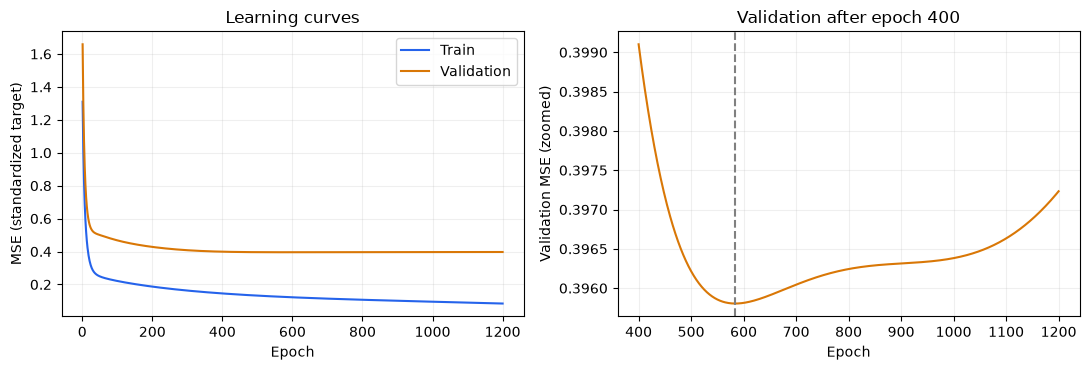

In [4]:
# history = train_demo(lr=0.03, epochs=1200)
# selected = history[history["epoch"].isin([1,5,100,300,600,1200])]
# best_row = ...
# 표와 그래프를 출력하고 최저점과 마지막 기록을 비교하세요.

history = train_demo(lr=0.03,epochs=1200)
selected = history[history['epoch'].isin([1,5,100,300,600,1200])]
best_row = history.loc[history['valid_loss'].idxmin()]
print(selected.round(9).to_string(index=False))
print('검증 최저 행:',best_row.to_dict())
print('마지막 행:',history.iloc[-1].to_dict())
fig, axes = plt.subplots(1,2,figsize=(11,3.8))
plot_pair(history,axes[0],'Learning curves')
late = history[history['epoch'] >= 400]
axes[1].plot(late['epoch'],late['valid_loss'],color='#d97706')
axes[1].axvline(best_row['epoch'],linestyle='--',color='gray')
axes[1].set(xlabel='Epoch',ylabel='Validation MSE (zoomed)',title='Validation after epoch 400')
axes[1].grid(alpha=0.2)
fig.tight_layout()
plt.show()


#### 답변 작성란

**계산·관찰 결과:**

- 출력 표·계산값 또는 후보 시점: 주요 기록은 다음과 같다.

| epoch | train_loss | valid_loss |
| --- | --- | --- |
| 1 | 1.3098373 | 1.65869152 |
| 5 | 0.821425689 | 1.07078109 |
| 100 | 0.221290716 | 0.467928246 |
| 300 | 0.163064493 | 0.408041446 |
| 600 | 0.122144287 | 0.39581305 |
| 1200 | 0.0842713355 | 0.397232468 |
검증 최저: epoch 584: 학습 0.12361735, 검증 0.395804714
- 그래프에서 읽은 구간·변화와 근거: epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 증가량=0.00142775393, 최저 대비 약 0.360721812%이다. 전체 그래프와 400 epoch 이후 확대 그래프를 함께 읽었다.

**Q1. 초기 구간에서 두 손실이 함께 내려가는 것은 무엇을 의미하나요?**

- 내 답변: 학습 데이터에 더 잘 맞춰지는 동시에 검증 오차도 줄어, 초기에는 새로운 표본에 대한 적합도도 개선되는 모습을 보인다.
- 수치·코드·비교 결과에 근거한 이유: epoch 1: 학습 1.3098373, 검증 1.65869152 → epoch 100: 학습 0.221290716, 검증 0.467928246. 검증을 기울기 업데이트에 쓰지 않아도 오차가 줄어들었다.

**Q2. 검증 최저 시점과 마지막 시점의 두 손실을 비교해 어떤 징후를 설명할 수 있나요? 검증 손실의 악화 폭도 함께 말하세요.**

- 내 답변: 학습 손실은 더 줄지만 검증 최저점 이후 검증 손실이 소폭 증가해 과적합 징후를 볼 수 있다.
- 수치·코드·비교 결과에 근거한 이유: epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 증가량=0.00142775393, 최저 대비 약 0.360721812%이다.

**Q3. 검증 손실이 학습 손실보다 크다는 이유만으로 과적합을 확정할 수 있나요? 확대 그림을 해석할 때 무엇을 주의해야 하나요?**

- 내 답변: 아니다. 데이터 난이도·표본 수 차이만으로도 격차가 생길 수 있다. 확대된 y축은 작은 차이도 크게 보이게 하므로 실제 증가량과 전체 규모를 함께 봐야 한다.
- 수치·코드·비교 결과에 근거한 이유: 최저 검증 0.395804714와 마지막 0.397232468의 차이는 0.00142775393이다. 선의 기울기만으로 심한 악화라고 과장하지 않는다.


---

## 실습 2. 학습 상태 진단과 개선 전략


### 문제 2-1. 네 가지 기록에서 근거 찾기

#### 문제 설명

같은 데이터·모델·초기값에서 학습률 또는 학습 횟수를 달리한 실제 기록을 비교합니다. A·B는 실습 1의 기록에서 구간을 고르고 C·D는 새로 학습합니다.

| 사례 | 설정 및 관찰 구간 |
|---|---|
| A | 학습률 0.03, 처음 5 epoch만 학습했다고 가정한 기록 |
| B | 학습률 0.03, 전체 1200 epoch 중 400 epoch 이후 기록 |
| C | 학습률 0.00001, 300 epoch |
| D | 학습률 0.8, 12 epoch |

#### 요구사항

1. A는 `history[history["epoch"] <= 5]`, B는 `history[history["epoch"] >= 400]`으로 고르세요.
2. C는 `train_demo(lr=0.00001, epochs=300)`, D는 `train_demo(lr=0.8, epochs=12)`로 만드세요.
3. 각 사례의 첫·마지막 학습 손실과 검증 손실을 표로 정리하세요.
4. 2×2 그래프를 그리세요. D만 `plot_pair(..., log_scale=True)`를 사용하세요. 나머지는 일반 축으로 그립니다.
5. 아래 질문에서 **상태 이름 + 숫자 또는 추세 + 확인할 설정**을 함께 설명하세요.

#### 작성 도움말

`frame.iloc[0]`은 첫 행, `frame.iloc[-1]`은 마지막 행입니다. `fig, axes = plt.subplots(2, 2, figsize=(11, 7))`로 네 개의 그림 공간을 만들고 `axes.flat`으로 차례대로 사용할 수 있습니다.

**D의 로그 축:** 같은 세로 간격이 같은 차이가 아니라 같은 배수를 나타냅니다. `1e+06`은 1,000,000입니다. 다른 그림과 선의 경사만 직접 비교하지 마세요. D의 학습률 0.8은 발산 관찰을 위한 설정이며 다른 모든 모델에서 발산하는 경계값은 아닙니다.

#### 해석 질문

**Q1.** A를 이후 300 epoch의 결과와 비교하면 어떤 상태의 징후가 있나요? 모델이 너무 작다는 결론까지 낼 수 있나요?

**Q2.** B에는 어떤 징후가 있나요? 어느 두 손실의 변화가 근거인가요?

**Q3.** C는 완전히 학습이 멈춘 것인가요? 이번 설정에서 우선 확인할 원인은 무엇인가요?

**Q4.** D를 검증 손실만 나빠지는 과적합과 어떻게 구별하나요? 반드시 NaN이 나와야 발산을 의심할 수 있나요?

**Q5.** 과소적합·학습 정체를 동시에 말할 수 있나요? 낮은 손실에서 두 곡선이 평평해졌을 때도 반드시 문제인가요?

#### 제출 결과

사례별 처음·마지막 손실 표, 2×2 그래프, Q1~Q5 답변.


case point  epoch   train_loss   valid_loss
   A first      1 1.309837e+00 1.658692e+00
   A  last      5 8.214257e-01 1.070781e+00
   B first    400 1.455337e-01 3.991014e-01
   B  last   1200 8.427134e-02 3.972325e-01
   C first      1 1.520809e+00 1.914466e+00
   C  last    300 1.498685e+00 1.887762e+00
   D first      1 3.293819e+00 3.365895e+00
   D  last     12 9.245294e+22 6.852090e+22


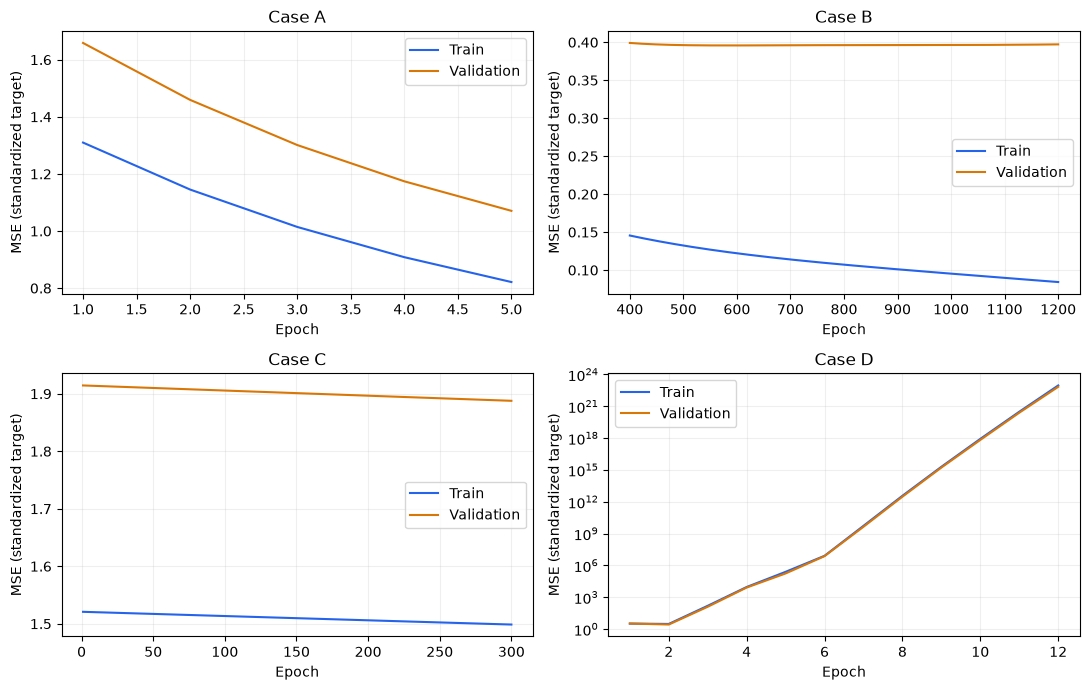

In [5]:
# case_a = history[history["epoch"] <= 5].copy()
# case_b = history[history["epoch"] >= 400].copy()
# case_c = train_demo(lr=..., epochs=300)
# case_d = train_demo(lr=..., epochs=12)
# cases = {"A": case_a, "B": case_b, "C": case_c, "D": case_d}
# 첫 행과 마지막 행을 표로 만들고 그래프를 그리세요.

case_a = history[history['epoch'] <= 5].copy()
case_b = history[history['epoch'] >= 400].copy()
case_c = train_demo(lr=0.00001,epochs=300)
case_d = train_demo(lr=0.8,epochs=12)
cases = {'A':case_a,'B':case_b,'C':case_c,'D':case_d}
case_rows = []
for label, frame in cases.items():
    for point, row in [('first',frame.iloc[0]),('last',frame.iloc[-1])]:
        case_rows.append({'case':label,'point':point,'epoch':int(row['epoch']),
                          'train_loss':row['train_loss'],'valid_loss':row['valid_loss']})
case_summary = pd.DataFrame(case_rows)
print(case_summary.to_string(index=False))
fig, axes = plt.subplots(2,2,figsize=(11,7))
for ax,(label,frame) in zip(axes.flat,cases.items()):
    plot_pair(frame,ax,'Case '+label,log_scale=(label=='D'))
fig.tight_layout()
plt.show()


#### 답변 작성란

**계산·관찰 결과:**

- 출력 표·계산값 또는 후보 시점: 사례별 첫·마지막 기록은 다음과 같다.

| case | point | epoch | train_loss | valid_loss |
| --- | --- | --- | --- | --- |
| A | first | 1 | 1.3098373 | 1.65869152 |
| A | last | 5 | 0.821425689 | 1.07078109 |
| B | first | 400 | 0.145533728 | 0.399101442 |
| B | last | 1200 | 0.0842713355 | 0.397232468 |
| C | first | 1 | 1.52080923 | 1.91446636 |
| C | last | 300 | 1.49868493 | 1.8877622 |
| D | first | 1 | 3.29381907 | 3.36589536 |
| D | last | 12 | 9.24529429e+22 | 6.85209009e+22 |

- 그래프에서 읽은 구간·변화와 근거: A는 초기 학습 부족, B는 최저점 뒤 소폭 과적합 징후, C는 매우 느린 학습·정체처럼 보이는 상태, D는 발산 양상이다. D의 y축만 로그 축이다.

**Q1. A를 이후 300 epoch의 결과와 비교하면 어떤 상태의 징후가 있나요? 모델이 너무 작다는 결론까지 낼 수 있나요?**

- 내 답변: A는 아직 학습이 충분히 진행되지 않은 과소적합·학습 부족의 징후이다. 같은 모델을 더 학습하면 개선되므로 모델이 너무 작다고 단정할 수 없다.
- 수치·코드·비교 결과에 근거한 이유: epoch 1: 학습 1.3098373, 검증 1.65869152 → epoch 5: 학습 0.821425689, 검증 1.07078109. 300 epoch 결과는 epoch 300: 학습 0.163064493, 검증 0.408041446.

**Q2. B에는 어떤 징후가 있나요? 어느 두 손실의 변화가 근거인가요?**

- 내 답변: B 구간은 처음에는 더 개선되다가 검증 최저점을 지나 학습 손실 감소와 검증 손실 소폭 증가가 함께 나타나는 과적합 징후가 있다.
- 수치·코드·비교 결과에 근거한 이유: epoch 400: 학습 0.145533728, 검증 0.399101442 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 구간 전체가 처음부터 악화한 것은 아니며 최저점 이후 비교는 epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 증가량=0.00142775393, 최저 대비 약 0.360721812%이다.

**Q3. C는 완전히 학습이 멈춘 것인가요? 이번 설정에서 우선 확인할 원인은 무엇인가요?**

- 내 답변: 완전히 멈춘 것은 아니다. 손실이 조금씩 내려가지만 이 학습 횟수 안에서는 개선이 매우 느리다. 우선 지나치게 작은 학습률 0.00001을 확인한다.
- 수치·코드·비교 결과에 근거한 이유: epoch 1: 학습 1.52080923, 검증 1.91446636 → epoch 300: 학습 1.49868493, 검증 1.8877622. 같은 초기값·모델의 lr=0.03, 300 epoch와 비교하여 학습률 영향을 점검했다.

**Q4. D를 검증 손실만 나빠지는 과적합과 어떻게 구별하나요? 반드시 NaN이 나와야 발산을 의심할 수 있나요?**

- 내 답변: D는 학습 손실까지 큰 규모로 급증하므로 검증만 악화하는 과적합과 구별한다. NaN 없이 큰 유한값이 반복 증가해도 발산을 의심할 수 있다.
- 수치·코드·비교 결과에 근거한 이유: epoch 1: 학습 3.29381907, 검증 3.36589536 → epoch 12: 학습 9.24529429e+22, 검증 6.85209009e+22. 학습률 0.8이 이번 설정에서 불안정했다는 뜻이며 모든 모델의 보편적 발산 경계값은 아니다. 로그 축의 같은 간격은 같은 배수를 뜻한다.

**Q5. 과소적합·학습 정체를 동시에 말할 수 있나요? 낮은 손실에서 두 곡선이 평평해졌을 때도 반드시 문제인가요?**

- 내 답변: 가능하다. 과소적합은 충분히 맞추지 못한 상태, 정체는 개선 속도가 느린 추세를 나타내므로 동시에 설명할 수 있다. 낮은 손실에서 평평한 곡선은 수렴일 수도 있어 반드시 문제는 아니다.
- 수치·코드·비교 결과에 근거한 이유: 현재 손실 수준·초기 대비 개선량·검증 추세·비교 설정을 함께 봐야 한다. C는 높은 손실에서 느리게 개선하지만 좋은 모델의 낮은 손실 plateau와 구분해야 한다.


### 문제 2-2. 설정 하나를 바꾸고 개선 방향 확인하기

#### 문제 설명

기록의 상태에 따라 개선 방법이 달라집니다. 모든 문제에 무조건 학습 횟수를 늘리거나 학습률을 높이는 방식으로 대응하지 않습니다. 앞에서 만든 기록을 재사용해 **같은 조건에서 설정 하나가 다른 결과**를 비교하세요.

#### 요구사항

1. A의 5 epoch 결과와 학습률 0.03의 300 epoch 결과를 비교하세요. 바뀐 것은 학습 횟수입니다.
2. C의 300 epoch 결과와 학습률 0.03의 300 epoch 결과를 비교하세요. 바뀐 것은 학습률입니다.
3. D의 12 epoch 결과와 학습률 0.03의 12 epoch 결과를 비교하세요. 여기서도 바뀐 것은 학습률입니다.
4. 세 비교에서 학습·검증 손실의 전후 값을 표로 출력하세요.
5. B에 대해서는 새 기법을 구현하지 않고, 과적합 징후에 대응할 개선 전략 한 가지를 제안하세요.

#### 작성 도움말

```python
def at_epoch(frame, epoch):
    return frame.loc[frame["epoch"] == epoch].iloc[0]
```

이 함수를 정의하면 `at_epoch(history, 300)`으로 비교 행을 선택할 수 있습니다. `history`의 12·300 epoch 기록은 같은 초기값에서 학습한 해당 시점의 실제 결과이므로 다시 학습하지 않고 사용할 수 있습니다.

#### 해석 질문

**Q1.** A·C·D는 각각 무엇을 바꾸었고 두 손실은 어느 방향으로 변했나요?

**Q2.** B에 맞는 개선 전략은 무엇인가요? Dropout·Weight Decay를 강하게 적용하거나 Batch Normalization을 넣으면 언제나 해결되나요?

**Q3.** 비교할 때 다른 조건을 같게 유지하는 이유는 무엇인가요? 학습률 0.03이 모든 문제의 정답인가요?

#### 제출 결과

세 가지 전후 비교 표, B의 개선 전략, Q1~Q3 답변.


In [6]:
def at_epoch(frame, epoch):
    return frame.loc[frame["epoch"] == epoch].iloc[0]

# A: at_epoch(history, 5)와 at_epoch(history, 300)
# C: at_epoch(case_c, 300)과 at_epoch(history, 300)
# D: at_epoch(case_d, 12)와 at_epoch(history, 12)
# 각 비교의 학습·검증 손실 전후 값을 표로 정리하세요.

comparison_rows = []
for label, before, after, setting in [
    ('A',at_epoch(history,5),at_epoch(history,300),'epochs 5 -> 300; lr=0.03'),
    ('C',at_epoch(case_c,300),at_epoch(history,300),'lr 0.00001 -> 0.03; epochs=300'),
    ('D',at_epoch(case_d,12),at_epoch(history,12),'lr 0.8 -> 0.03; epochs=12')]:
    comparison_rows.append({'case':label,'change':setting,'train_before':before['train_loss'],
        'train_after':after['train_loss'],'valid_before':before['valid_loss'],'valid_after':after['valid_loss']})
comparisons = pd.DataFrame(comparison_rows)
print(comparisons.to_string(index=False))


case                         change  train_before  train_after  valid_before  valid_after
   A       epochs 5 -> 300; lr=0.03  8.214257e-01     0.163064  1.070781e+00     0.408041
   C lr 0.00001 -> 0.03; epochs=300  1.498685e+00     0.163064  1.887762e+00     0.408041
   D      lr 0.8 -> 0.03; epochs=12  9.245294e+22     0.491047  6.852090e+22     0.700190


#### 답변 작성란

**계산·관찰 결과:**

- 출력 표·계산값 또는 후보 시점: 설정별 전후 비교는 다음과 같다.

| case | change | train_before | train_after | valid_before | valid_after |
| --- | --- | --- | --- | --- | --- |
| A | epochs 5 -> 300; lr=0.03 | 0.821425689 | 0.163064493 | 1.07078109 | 0.408041446 |
| C | lr 0.00001 -> 0.03; epochs=300 | 1.49868493 | 0.163064493 | 1.8877622 | 0.408041446 |
| D | lr 0.8 -> 0.03; epochs=12 | 9.24529429e+22 | 0.491047076 | 6.85209009e+22 | 0.700190227 |

- 그래프에서 읽은 구간·변화와 근거: A는 횟수만, C·D는 학습률만 바꾸어 각기 동일 횟수에서 비교했다. 세 경우 모두 학습·검증 손실이 낮아졌다.

**Q1. A·C·D는 각각 무엇을 바꾸었고 두 손실은 어느 방향으로 변했나요?**

- 내 답변: A는 lr=0.03에서 5→300 epoch, C는 300 epoch에서 lr=0.00001→0.03, D는 12 epoch에서 lr=0.8→0.03으로 바꾸었다. 모두 두 손실이 감소했다.
- 수치·코드·비교 결과에 근거한 이유: 설정별 전후 비교는 다음과 같다.

| case | change | train_before | train_after | valid_before | valid_after |
| --- | --- | --- | --- | --- | --- |
| A | epochs 5 -> 300; lr=0.03 | 0.821425689 | 0.163064493 | 1.07078109 | 0.408041446 |
| C | lr 0.00001 -> 0.03; epochs=300 | 1.49868493 | 0.163064493 | 1.8877622 | 0.408041446 |
| D | lr 0.8 -> 0.03; epochs=12 | 9.24529429e+22 | 0.491047076 | 6.85209009e+22 | 0.700190227 |


**Q2. B에 맞는 개선 전략은 무엇인가요? Dropout·Weight Decay를 강하게 적용하거나 Batch Normalization을 넣으면 언제나 해결되나요?**

- 내 답변: B에는 검증 개선이 멈추면 Early Stopping하고 최적 체크포인트를 복원하는 전략을 제안한다. Dropout·Weight Decay를 강하게 적용하거나 BN을 추가한다고 항상 해결되지는 않는다.
- 수치·코드·비교 결과에 근거한 이유: 최저점 이후 학습은 개선되지만 검증은 소폭 악화한다. 정규화 강도가 지나치면 과소적합이 생길 수 있으며 BN은 과적합 전용 해결책이 아니다. 여기서는 기법 적용 실험은 하지 않았다.

**Q3. 비교할 때 다른 조건을 같게 유지하는 이유는 무엇인가요? 학습률 0.03이 모든 문제의 정답인가요?**

- 내 답변: 다른 조건을 고정해야 차이가 변경한 설정 때문인지 해석하기 쉽다. 0.03은 이번 데이터·초기값·모델에서의 비교 설정이지 모든 문제의 정답이 아니다.
- 수치·코드·비교 결과에 근거한 이유: C·D의 변경 전후는 각각 300·12 epoch로 맞추었고, 데이터 분리·표준화·모델·초기 난수 시드를 유지했다. 여러 설정을 동시에 바꾸면 원인 구분이 어려워진다.


---

## 기초 과제. 근거를 붙여 학습 결과 선택하기


### 문제 3-1. 가장 작은 격차가 가장 좋은 결과일까요?

#### 문제 설명

실습 1의 기록에서 **100·584·1200 epoch**를 후보로 제시합니다. 각각의 학습 손실, 검증 손실, 손실 차이를 비교하고 가장 적절한 후보를 선택하세요. 새로운 모델을 구현하는 과제가 아닙니다.

#### 요구사항

1. `history`에서 세 후보 행을 골라 `.copy()`로 저장하세요.
2. `gap = valid_loss - train_loss` 열을 추가하세요.
3. 학습 손실이 가장 작은 후보, 검증 손실이 가장 작은 후보, gap이 가장 작은 후보를 각각 찾으세요.
4. 검증 결과를 기준으로 선택할 후보 한 개와 그 이유를 2~3문장으로 작성하세요.

#### 작성 도움말

`candidates = history[history["epoch"].isin([100, 584, 1200])].copy()`로 세 행을 고릅니다. `.idxmin()`과 `.loc[]`를 사용하면 원하는 열이 가장 작은 행을 찾을 수 있습니다. 여기서 gap은 단순한 차이값이며 별도의 학습 손실 함수가 아닙니다.

#### 해석 질문

**Q1.** 학습 손실·검증 손실·gap이 각각 가장 작은 후보는 몇 epoch인가요? 검증 기준으로 무엇을 선택하나요?

**Q2.** gap이 가장 작다는 이유만으로 가장 좋은 모델이라고 말할 수 없는 이유는 무엇인가요?

**Q3.** 선택한 검증 최저값을 새로운 데이터에서 보장되는 성능이라고 발표해도 되나요? 선택 근거와 결과의 한계를 포함하여 2~3문장으로 정리하세요.

#### 제출 결과

후보 비교 표, 세 가지 최소값의 epoch, Q1~Q3 답변.


In [7]:
# candidates = history[history["epoch"].isin([100,584,1200])].copy()
# candidates["gap"] = ...
# train_choice = ...
# valid_choice = ...
# gap_choice = ...
# print(candidates)

candidates = history[history['epoch'].isin([100,584,1200])].copy()
candidates['gap'] = candidates['valid_loss'] - candidates['train_loss']
train_choice = candidates.loc[candidates['train_loss'].idxmin()]
valid_choice = candidates.loc[candidates['valid_loss'].idxmin()]
gap_choice = candidates.loc[candidates['gap'].idxmin()]
print(candidates.round(9).to_string(index=False))
print('최소 학습 손실 epoch:',int(train_choice['epoch']))
print('최소 검증 손실 epoch:',int(valid_choice['epoch']))
print('최소 gap epoch:',int(gap_choice['epoch']))


 epoch  train_loss  valid_loss      gap
   100    0.221291    0.467928 0.246638
   584    0.123617    0.395805 0.272187
  1200    0.084271    0.397232 0.312961
최소 학습 손실 epoch: 1200
최소 검증 손실 epoch: 584
최소 gap epoch: 100


#### 답변 작성란

**계산·관찰 결과:**

- 출력 표·계산값 또는 후보 시점: 후보 표는 다음과 같다.

| epoch | train_loss | valid_loss | gap |
| --- | --- | --- | --- |
| 100 | 0.221291 | 0.467928 | 0.246638 |
| 584 | 0.123617 | 0.395805 | 0.272187 |
| 1200 | 0.084271 | 0.397232 | 0.312961 |

- 그래프에서 읽은 구간·변화와 근거: 학습 손실 최소 1200 epoch, 검증 손실 최소 584 epoch, gap 최소 100 epoch. 검증 성능을 선택 기준으로 삼으면 584 epoch를 고른다.

**Q1. 학습 손실·검증 손실·gap이 각각 가장 작은 후보는 몇 epoch인가요? 검증 기준으로 무엇을 선택하나요?**

- 내 답변: 학습 손실 최소 1200 epoch, 검증 손실 최소 584 epoch, gap 최소 100 epoch이다. 검증 기준으로 584 epoch를 선택한다.
- 수치·코드·비교 결과에 근거한 이유: 후보별 해당 열을 idxmin으로 비교했다. 학습은 계속 줄어도 검증은 최저점 이후 증가할 수 있어 서로 다른 후보가 선택된다.

**Q2. gap이 가장 작다는 이유만으로 가장 좋은 모델이라고 말할 수 없는 이유는 무엇인가요?**

- 내 답변: 두 손실이 모두 크면 격차는 작아도 예측은 나쁠 수 있다. gap은 두 손실의 단순 차이일 뿐 검증 오차 자체를 최소화하는 기준이 아니다.
- 수치·코드·비교 결과에 근거한 이유: gap 최소 후보 100의 검증 손실 0.467928는 검증 최소 후보의 0.395805보다 크다.

**Q3. 선택한 검증 최저값을 새로운 데이터에서 보장되는 성능이라고 발표해도 되나요? 선택 근거와 결과의 한계를 포함하여 2~3문장으로 정리하세요.**

- 내 답변: 세 후보 중 검증 MSE가 가장 낮은 584 epoch(0.395805)를 선택한다. 이 검증 집합은 시점 선택에 사용되었으므로 해당 값을 새로운 데이터에서 보장되는 성능으로 발표할 수 없다. 최종 성능은 선택에 관여하지 않은 별도 테스트로 확인해야 한다.
- 수치·코드·비교 결과에 근거한 이유: 검증 손실은 선택의 근거이지 일반화 성능의 보장값이 아니다. 이 노트북은 최저 행을 골랐지만 가중치 저장·복원과 최종 테스트는 수행하지 않았다.


## 실습 마무리

손실 계산에서 상태 진단과 개선 전략, 후보 선택까지 이어지는 흐름을 정리합니다. 아래 여섯 문항은 이미 배운 내용을 자기 말로 설명하는 **기초 복습**입니다. 새 모델 구현이나 추가 기법의 성능 실험을 요구하지 않습니다.

### 마무리 질문

**마무리 Q1.** 표준화된 예측값 0이 실제로 무엇을 예측한다는 뜻인지 설명하세요. 기준 모델의 전체 학습 MSE, 검증 MSE, 처음 세 행 MSE와 서로 다른 이유를 쓰세요.

**마무리 Q2.** 584와 1200 epoch의 학습·검증 손실을 비교하여 상태를 설명하세요. 확대 그림의 기울기만 보고 악화를 판단하면 안 되는 이유는 무엇인가요?

**마무리 Q3.** A·B·C·D의 상태를 각각 수치 또는 추세와 연결하세요. C가 완전히 멈춘 것인지, D는 NaN이 없어도 문제가 있는지 설명하세요.

**마무리 Q4.** A·C·D에서는 각각 어떤 설정을 바꾸어 확인했나요? C와 D를 모두 기준 모델의 1200 epoch와 비교하면 어떤 문제가 있나요?

**마무리 Q5.** 학습 손실·검증 손실·gap을 기준으로 한 세 후보의 선택 결과를 쓰세요. gap이 작다는 것이 검증 성능이 좋다는 뜻은 아닌 이유를 설명하세요.

**마무리 Q6.** 이번에 실제로 실행해 확인한 내용과 개선 전략으로만 제안한 내용을 구분하세요. 검증 최저 행을 골랐으면 최적 가중치 복원과 최종 테스트 평가도 끝난 것인가요?

### 마무리 답변 작성란

**마무리 Q1. 표준화된 예측값 0이 실제로 무엇을 예측한다는 뜻인지 설명하세요. 기준 모델의 전체 학습 MSE, 검증 MSE, 처음 세 행 MSE와 서로 다른 이유를 쓰세요.**

- 내 답변: 표준화 예측 0은 원래 압축강도로 학습 평균 38.10325 MPa를 예측한다는 뜻이다. 기준 학습 MSE=1, 검증 MSE=1.22032007, 처음 3행 MSE=1.8150715.
- 계산값·관찰 구간·비교 근거: 학습 목표는 전체 80행 기준 평균 0·분산 1이라 기준 MSE=1이다. 검증과 처음 3행은 다른 값들의 제곱 평균이므로 1일 필요가 없다.

**마무리 Q2. 584와 1200 epoch의 학습·검증 손실을 비교하여 상태를 설명하세요. 확대 그림의 기울기만 보고 악화를 판단하면 안 되는 이유는 무엇인가요?**

- 내 답변: 584 이후 학습은 개선되나 검증은 소폭 악화하는 과적합 징후이다. 확대 축에서는 작은 차이도 커 보이므로 실제 값과 변화량을 확인한다.
- 계산값·관찰 구간·비교 근거: epoch 584: 학습 0.12361735, 검증 0.395804714 → epoch 1200: 학습 0.0842713355, 검증 0.397232468. 검증 증가량=0.00142775393, 최저 대비 약 0.360721812%이다.

**마무리 Q3. A·B·C·D의 상태를 각각 수치 또는 추세와 연결하세요. C가 완전히 멈춘 것인지, D는 NaN이 없어도 문제가 있는지 설명하세요.**

- 내 답변: A는 학습 부족, B는 최저점 이후 소폭 과적합, C는 작은 학습률로 매우 느린 개선, D는 학습·검증 손실 급증의 발산 양상이다. C는 완전 정지는 아니고 D는 NaN이 없어도 문제가 있다.
- 계산값·관찰 구간·비교 근거: A: epoch 1: 학습 1.3098373, 검증 1.65869152 → epoch 5: 학습 0.821425689, 검증 1.07078109; B: epoch 400: 학습 0.145533728, 검증 0.399101442 → epoch 1200: 학습 0.0842713355, 검증 0.397232468; C: epoch 1: 학습 1.52080923, 검증 1.91446636 → epoch 300: 학습 1.49868493, 검증 1.8877622; D: epoch 1: 학습 3.29381907, 검증 3.36589536 → epoch 12: 학습 9.24529429e+22, 검증 6.85209009e+22

**마무리 Q4. A·C·D에서는 각각 어떤 설정을 바꾸어 확인했나요? C와 D를 모두 기준 모델의 1200 epoch와 비교하면 어떤 문제가 있나요?**

- 내 답변: A는 횟수 5→300, C는 학습률 0.00001→0.03(300회 고정), D는 0.8→0.03(12회 고정)으로 바꾸었다. C·D를 1200회와 비교하면 학습률과 횟수가 함께 달라져 원인을 구분하기 어렵다.
- 계산값·관찰 구간·비교 근거: 설정별 전후 비교는 다음과 같다.

| case | change | train_before | train_after | valid_before | valid_after |
| --- | --- | --- | --- | --- | --- |
| A | epochs 5 -> 300; lr=0.03 | 0.821425689 | 0.163064493 | 1.07078109 | 0.408041446 |
| C | lr 0.00001 -> 0.03; epochs=300 | 1.49868493 | 0.163064493 | 1.8877622 | 0.408041446 |
| D | lr 0.8 -> 0.03; epochs=12 | 9.24529429e+22 | 0.491047076 | 6.85209009e+22 | 0.700190227 |


**마무리 Q5. 학습 손실·검증 손실·gap을 기준으로 한 세 후보의 선택 결과를 쓰세요. gap이 작다는 것이 검증 성능이 좋다는 뜻은 아닌 이유를 설명하세요.**

- 내 답변: 학습 손실 최소 1200 epoch, 검증 손실 최소 584 epoch, gap 최소 100 epoch. gap이 작아도 두 손실이 모두 클 수 있어 검증 성능이 좋다는 뜻은 아니다.
- 계산값·관찰 구간·비교 근거: 검증 기준으로는 584 epoch를 선택했다. 후보 표의 valid_loss와 gap을 따로 비교했다.

| epoch | train_loss | valid_loss | gap |
| --- | --- | --- | --- |
| 100 | 0.221290716 | 0.467928246 | 0.24663753 |
| 584 | 0.12361735 | 0.395804714 | 0.272187364 |
| 1200 | 0.0842713355 | 0.397232468 | 0.312961132 |


**마무리 Q6. 이번에 실제로 실행해 확인한 내용과 개선 전략으로만 제안한 내용을 구분하세요. 검증 최저 행을 골랐으면 최적 가중치 복원과 최종 테스트 평가도 끝난 것인가요?**

- 내 답변: 실제로 MSE·학습 기록·네 사례·설정별 비교·후보 선택을 계산했다. B의 Early Stopping·정규화 적용은 개선 전략으로만 제안했다. 검증 최저 행 선택만으로 가중치 복원·테스트 평가까지 끝난 것은 아니다.
- 계산값·관찰 구간·비교 근거: 이 노트북의 train_demo는 history만 반환하고 체크포인트를 저장하지 않는다. 별도 최적 가중치 저장·복원과 선택에 쓰지 않은 테스트 평가가 필요하다.


### 학습 완료 확인

- [ ] Training Loss와 Validation Loss의 데이터·단위·계산 범위를 구분합니다.
- [ ] 같은 시점의 두 손실과 시간에 따른 추세를 함께 설명할 수 있습니다.
- [ ] 네 상태의 이름에 실제 수치와 원인 후보를 붙일 수 있습니다.
- [ ] 확대 축·로그 축을 읽고 변화 규모를 과장하지 않습니다.
- [ ] 개선 방향에 맞춰 설정 하나를 바꾸고 비교 조건을 맞출 수 있습니다.
- [ ] gap만으로 고르지 않고 검증 손실과 결과의 한계를 설명할 수 있습니다.

정답 문장을 그대로 외우지 않아도 됩니다. 관찰한 수치·추세, 그로부터 판단할 수 있는 내용, 아직 확인하지 않은 내용이 구분되면 됩니다. 모호한 항목은 해당 문제의 코드 해설과 표로 돌아가 확인하세요.


## 제출 전 확인

- 실습 2개와 기초 과제 1개의 모든 질문에 답했나요?
- 두 손실의 데이터와 단위를 구분했나요?
- 진단에 상태 이름뿐 아니라 숫자·추세 근거를 적었나요?
- 작은 검증 손실 증가를 과장하지 않았나요?
- 정체와 과소적합이 겹칠 수 있음을 이해했나요?
- 개선 비교에서 무엇을 바꾸고 무엇을 유지했는지 설명했나요?
- 검증 결과와 최종 테스트 성능을 구분했나요?

## 주제별 이해 확인

| 주제 | 답안에서 확인할 내용 |
|---|---|
| 학습·검증 손실 | 어떤 데이터로 계산했는지, 표준화된 MSE가 무엇인지, 표본 수에 맞게 평균했는지 |
| Learning Curve | 축·범례·관찰 구간을 읽고, 검증 최저점 전후의 두 손실 변화를 구분했는지 |
| 과소적합 | 학습도 충분하지 않다는 근거를 비교 결과와 연결했는지 |
| 과적합 | 학습은 개선되지만 검증은 개선되지 않는 구간과 실제 악화 폭을 설명했는지 |
| 정체·발산 | 매우 느린 개선과 반복적인 급증을 구분하고, 정체와 과소적합이 겹칠 수 있음을 이해했는지 |
| 개선 전략 | 진단 근거에 맞는 변경을 제안하고, 다른 조건을 고정해 두 손실을 비교했는지 |
| 후보 선택 | gap만으로 고르지 않고 검증 손실과 흐름을 함께 보며, 결과의 한계를 설명했는지 |

답안의 문장이 예시와 완전히 같을 필요는 없습니다. 실제 출력 숫자·추세와 맞는 이유를 쉬운 말로 설명하면 됩니다. 제공된 강의 목차와 기존 실습을 기준으로 보완했으며, 별도로 제공되지 않은 교안 본문과의 세부 일치 여부까지 확인한 것은 아닙니다.
